# House Prices – House Prices Predictions
## Predict sales prices using regression
### Dataset [House prices dataset](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data)

## Exploring Data Analysis and Feature Engineering

In [1]:
import numpy as np
import pandas as pd

df_train = pd.read_csv('../data/train.csv')

### The first look at the data

In [2]:
TARGET = 'SalePrice'
display(df_train.head())
print(f'The shape of data: {df_train.shape}')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


The shape of data: (1460, 81)


Let's delete duplicates and check the shape again

In [3]:
df_train = df_train.drop_duplicates()
print(f'The shape of data: {df_train.shape}')
display(df_train.describe())
display(df_train.info())

The shape of data: (1460, 81)


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

None

### Checking Null values

In [4]:
display(df_train.isna().sum().sort_values(ascending=False).head(20))
display(df_train.isna().sum().sort_values(ascending=False).head(20) / df_train.shape[0] * 100)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Id                 0
dtype: int64

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageYrBlt      5.547945
GarageCond       5.547945
GarageType       5.547945
GarageFinish     5.547945
GarageQual       5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
Id               0.000000
dtype: float64

### Deleting unnecessary features with a lot of gaps in data ans ID feature

In [ ]:
df_train = df_train.drop(columns=['PoolQC', 'MiscFeature', 'Alley', 'Id'])
display(df_train.isna().sum().sort_values(ascending=False).head(20))
display(df_train.isna().sum().sort_values(ascending=False).head(20) / df_train.shape[0] * 100)

Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageFinish      81
GarageQual        81
GarageCond        81
GarageYrBlt       81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
BedroomAbvGr       0
BsmtHalfBath       0
BsmtFullBath       0
Functional         0
dtype: int64

Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
GarageYrBlt      5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtFinType1     2.534247
BsmtCond         2.534247
BsmtQual         2.534247
MasVnrArea       0.547945
Electrical       0.068493
BedroomAbvGr     0.000000
BsmtHalfBath     0.000000
BsmtFullBath     0.000000
Functional       0.000000
dtype: float64

### Feature `Fence` seems to be deleted, but target should be checked at it's dependence

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df_train['Fence'].value_counts()

Fence
MnPrv    157
GdPrv     59
GdWo      54
MnWw      11
Name: count, dtype: int64

To check it let's create a boxplot as it is a categorial feature

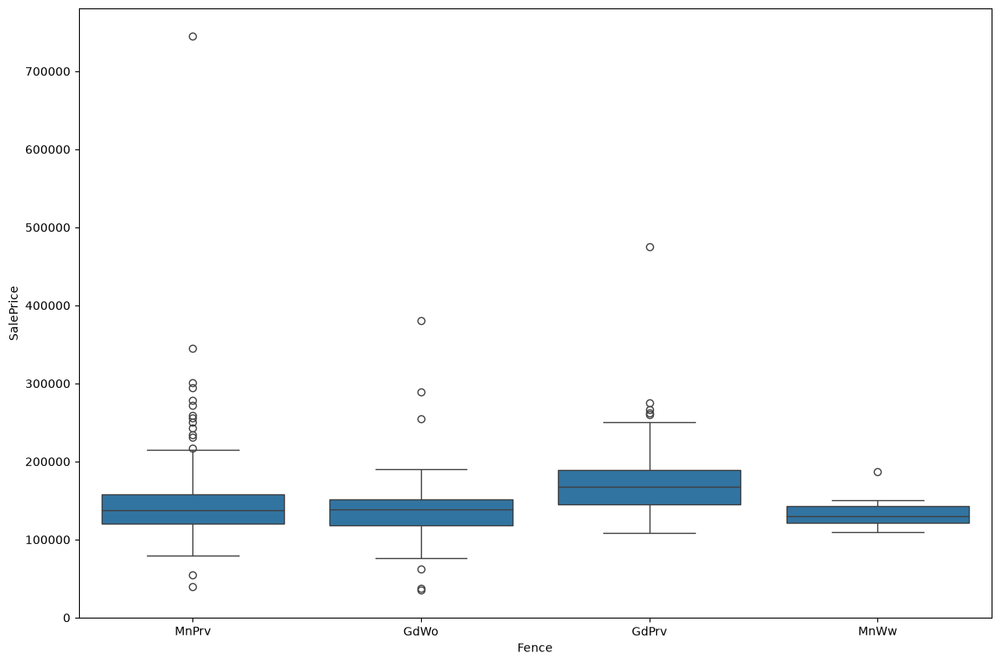

In [8]:
plt.figure(figsize=(12, 8))
df_train_fence = df_train[df_train['Fence'].isnull() == False]

sns.boxplot(data=df_train_fence, y=TARGET, x='Fence')
plt.tight_layout()

These blue boxes are on the equal level and have a lot of ejections, so that this feature should be dropped

In [9]:
df_train = df_train.drop(columns='Fence')

## Researching number features

In [10]:
num_columns = df_train.select_dtypes([int, float]).columns.to_list()
df_train[num_columns].isna().sum().sort_values(ascending=False)

LotFrontage      259
GarageYrBlt       81
MasVnrArea         8
OpenPorchSF        0
KitchenAbvGr       0
TotRmsAbvGrd       0
Fireplaces         0
GarageCars         0
GarageArea         0
WoodDeckSF         0
MSSubClass         0
BedroomAbvGr       0
3SsnPorch          0
ScreenPorch        0
PoolArea           0
MiscVal            0
MoSold             0
YrSold             0
EnclosedPorch      0
FullBath           0
HalfBath           0
BsmtFinSF2         0
LotArea            0
OverallQual        0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
BsmtFinSF1         0
BsmtUnfSF          0
BsmtHalfBath       0
TotalBsmtSF        0
1stFlrSF           0
2ndFlrSF           0
LowQualFinSF       0
GrLivArea          0
BsmtFullBath       0
SalePrice          0
dtype: int64

We have 3 number features with gapes, let's have a look at them

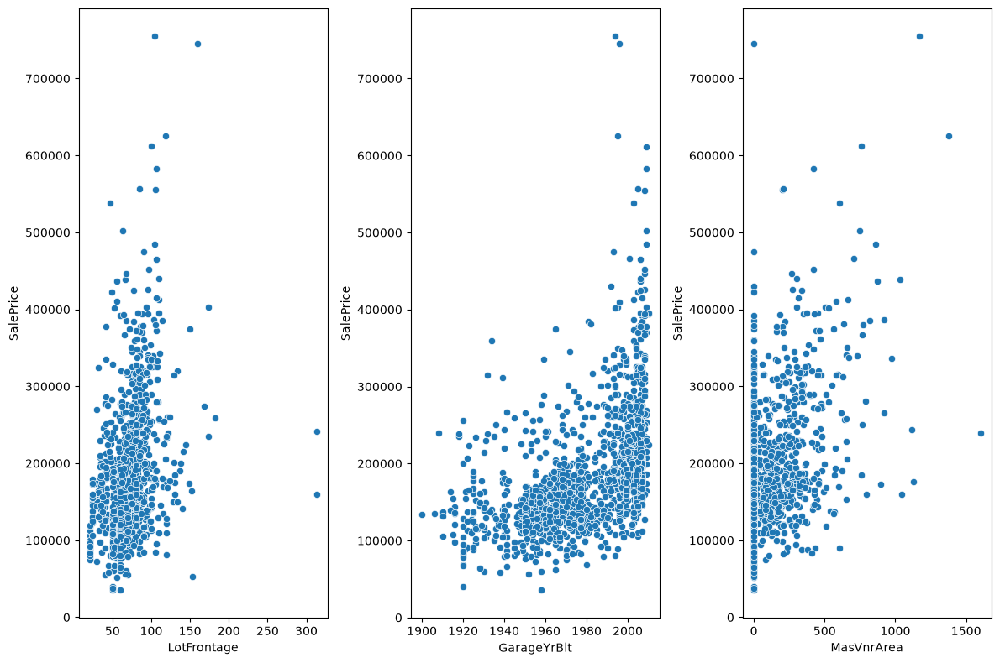

In [11]:
num_gaps_cols = ['LotFrontage', 'GarageYrBlt', 'MasVnrArea']

fig, axes = plt.subplots(1, 3,figsize=(12, 8))
for i in range(3):
    sns.scatterplot(data=df_train, x=num_gaps_cols[i], y=TARGET, ax=axes[i])
    
plt.tight_layout()
plt.show()

In [12]:
df_train['LotFrontage'] = df_train['LotFrontage'].fillna(df_train['LotFrontage'].mean())
df_train['GarageYrBlt'] = df_train['GarageYrBlt'].fillna(df_train['GarageYrBlt'].mean())
df_train['MasVnrArea'] = df_train['MasVnrArea'].fillna(df_train['MasVnrArea'].mode()[0])

<Axes: >

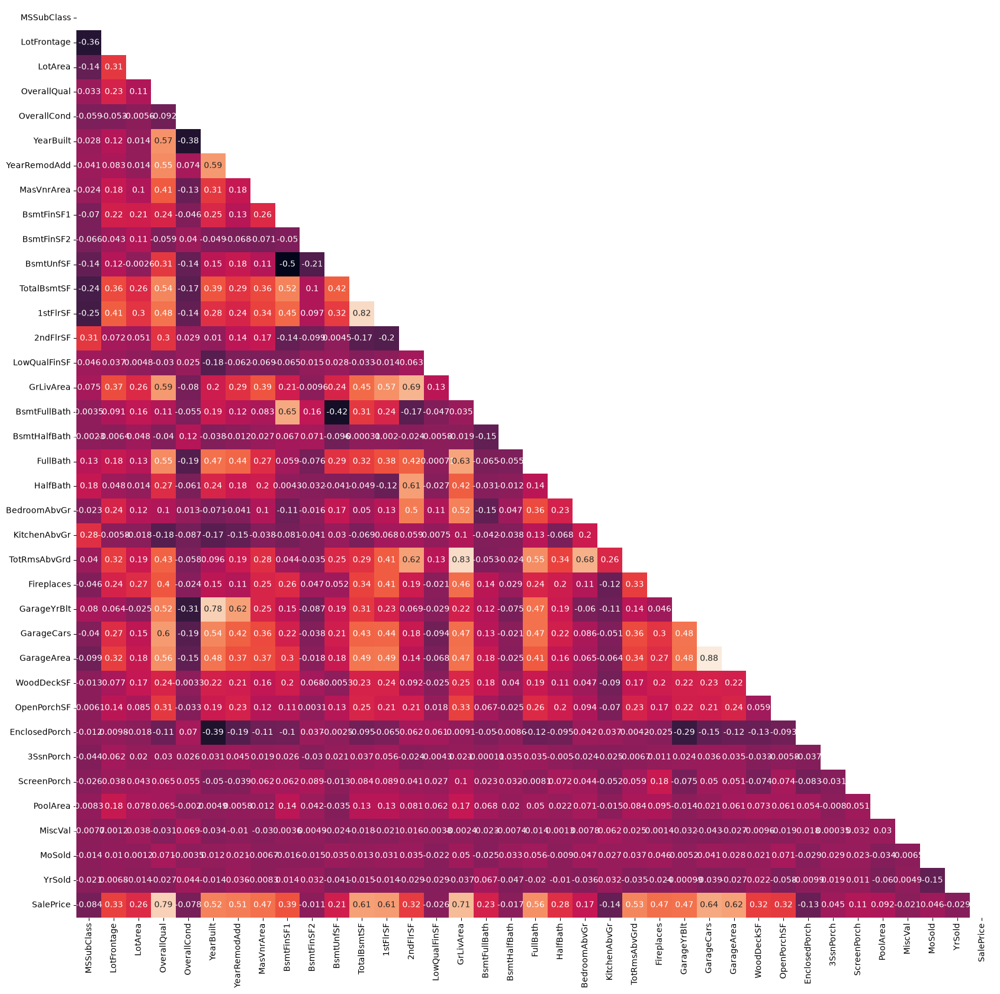

In [13]:
corr = df_train[num_columns].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(20,20))
sns.heatmap(corr, annot=True, cbar=False, mask=mask)

In [14]:
corr_features = [('GarageYrBlt', 'YearBuilt'),
                 ('TotRmsAbvGrd', 'GrLivArea'),
                 ('GarageArea', 'GarageCars'),
                 ('1stFlrSF', 'TotalBsmtSF')
                 ]

corr_list = []
for p in corr_features:
    for f in p:
        corr_list.append(f)

df_train[corr_list].isnull().sum().sort_values(ascending=False)

GarageYrBlt     0
YearBuilt       0
TotRmsAbvGrd    0
GrLivArea       0
GarageArea      0
GarageCars      0
1stFlrSF        0
TotalBsmtSF     0
dtype: int64

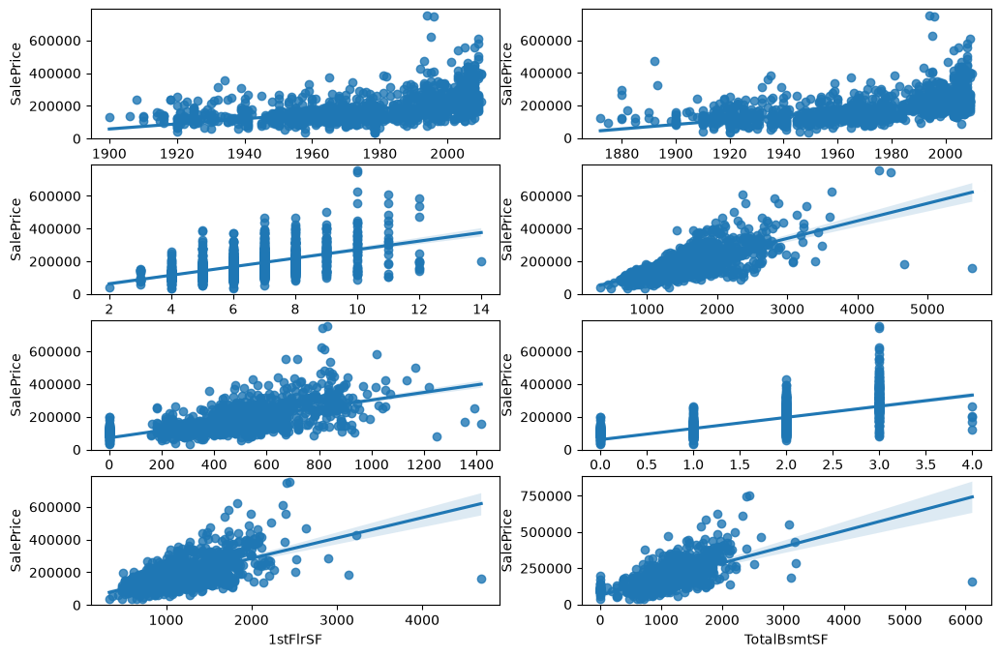

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), corr_list):
    sns.regplot(data=df_train, x=col, y=TARGET, ax=ax)

In [16]:
df_train = df_train.drop(columns=['GarageYrBlt', 'TotRmsAbvGrd', 'GarageCars', '1stFlrSF'])

### Researching categorial features

MasVnrType       59.726027
FireplaceQu      47.260274
GarageCond        5.547945
GarageQual        5.547945
GarageFinish      5.547945
GarageType        5.547945
BsmtExposure      2.602740
BsmtFinType2      2.602740
BsmtCond          2.534247
BsmtFinType1      2.534247
BsmtQual          2.534247
Electrical        0.068493
Heating           0.000000
MSZoning          0.000000
HeatingQC         0.000000
CentralAir        0.000000
Functional        0.000000
PavedDrive        0.000000
SaleType          0.000000
KitchenQual       0.000000
Foundation        0.000000
Street            0.000000
ExterCond         0.000000
LotShape          0.000000
LandContour       0.000000
Utilities         0.000000
LotConfig         0.000000
LandSlope         0.000000
Neighborhood      0.000000
Condition1        0.000000
Condition2        0.000000
BldgType          0.000000
HouseStyle        0.000000
RoofStyle         0.000000
RoofMatl          0.000000
Exterior1st       0.000000
Exterior2nd       0.000000
E

['MasVnrType',
 'FireplaceQu',
 'GarageCond',
 'GarageQual',
 'GarageFinish',
 'GarageType',
 'BsmtExposure',
 'BsmtFinType2',
 'BsmtCond',
 'BsmtFinType1',
 'BsmtQual',
 'Electrical']

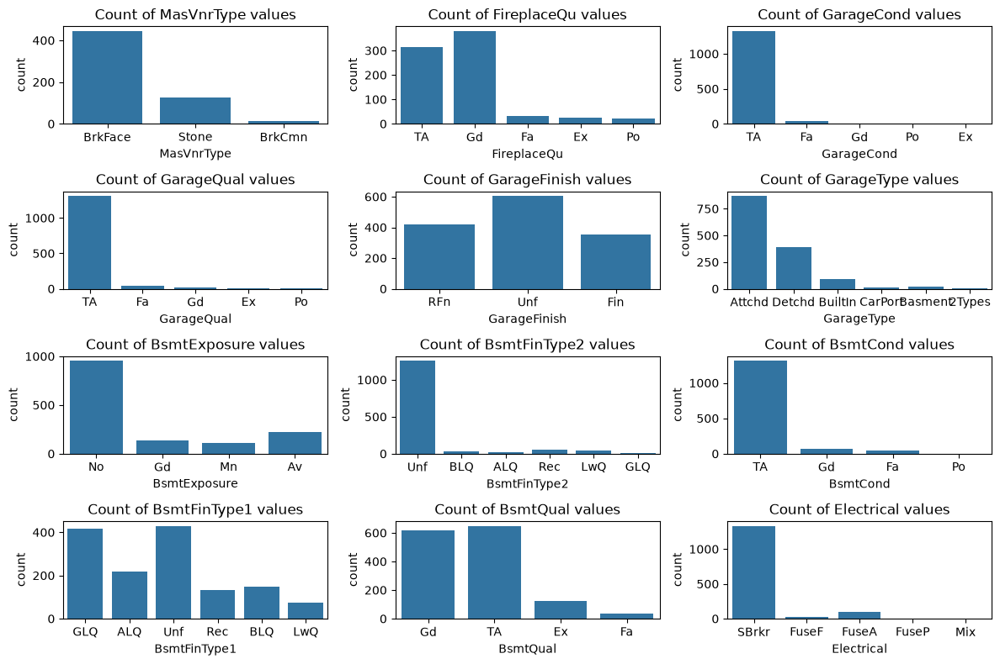

In [17]:
cat_features = df_train.select_dtypes(str).columns.to_list()
display(df_train[cat_features].isna().sum().sort_values(ascending=False) / df_train.shape[0] * 100)
cat_gap_cols = df_train[cat_features].isna().sum().sort_values(ascending=False).index[:12].to_list()
display(cat_gap_cols)

fig, axes = plt.subplots(4, 3, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_gap_cols):
    sns.countplot(data=df_train, x=col, ax=ax)
    ax.set_title(f'Count of {col} values')
    
plt.tight_layout()
    


In [18]:
df_train.loc[~df_train['GarageQual'].isin(['TA', 'Fa']), 'GarageQual'] = 'Other'
df_train.loc[~df_train['Electrical'].isin(['SBrkr', 'FuseA']), 'Electrical'] = 'Other'
df_train.loc[~df_train['GarageType'].isin(['Attchd', 'Detchd', 'Builtin']), 'GarageType'] = 'Other'
df_train.loc[df_train['BsmtFinType2'] != 'Unf', 'BsmtFinType2'] = 'Other'



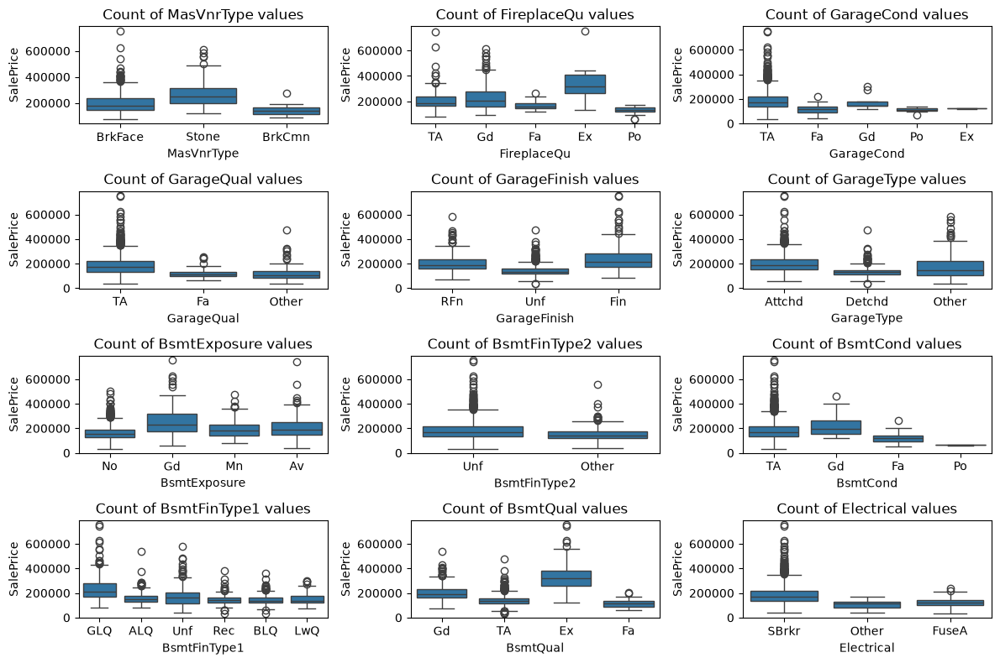

In [19]:
fig, axes = plt.subplots(4, 3, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_gap_cols):
    sns.boxplot(data=df_train, x=col, y=TARGET, ax=ax)
    ax.set_title(f'Count of {col} values')
    
plt.tight_layout()

In [20]:
df_train.select_dtypes(str).columns.to_list()

['MSZoning',
 'Street',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'SaleType',
 'SaleCondition']

In [21]:
cat_features = df_train.select_dtypes(str).columns.to_list()
len(cat_features)

cat_features_list = cat_features[:8]

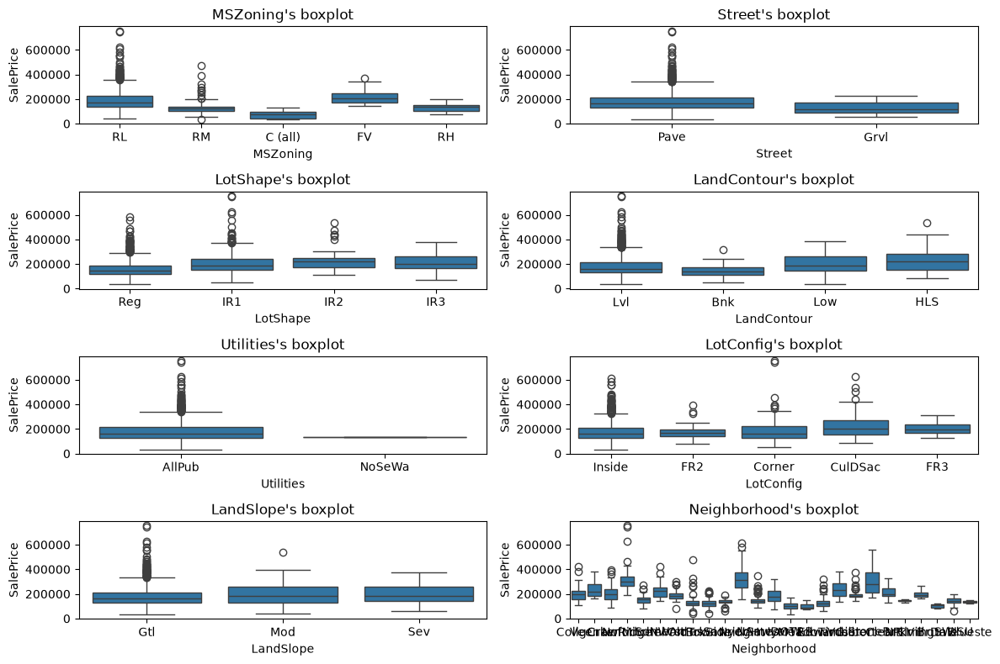

In [22]:
fig, axes = plt.subplots(4, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_features_list):
    sns.boxplot(data=df_train, x=col, y=TARGET, ax=ax)
    ax.set_title(f'{col}\'s boxplot')
    
plt.tight_layout()

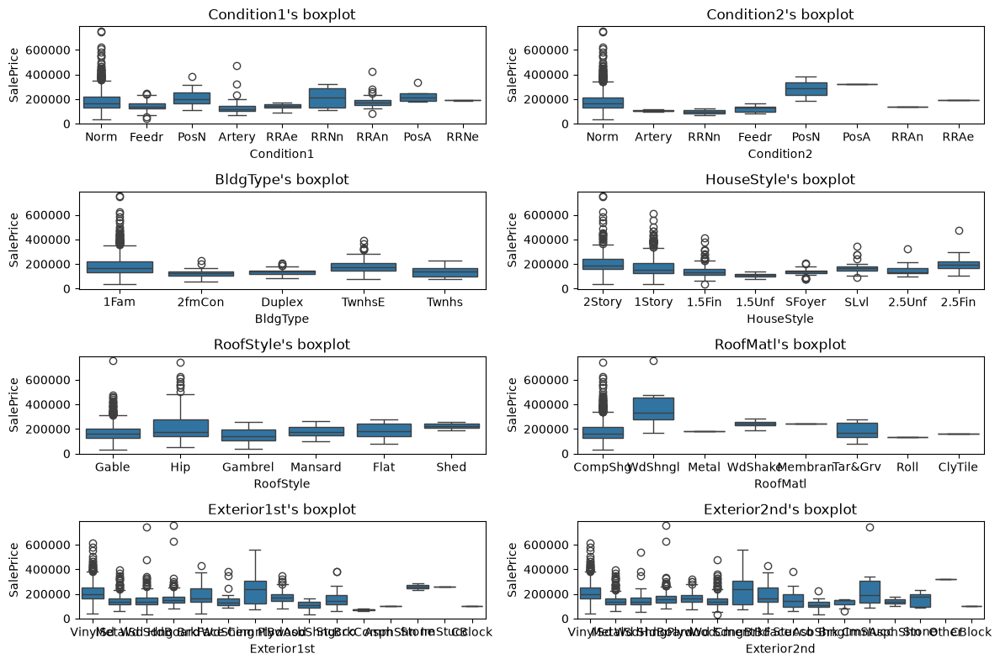

In [23]:
cat_features_list = cat_features[8:16]
fig, axes = plt.subplots(4, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_features_list):
    sns.boxplot(data=df_train, x=col, y=TARGET, ax=ax)
    ax.set_title(f'{col}\'s boxplot')
    
plt.tight_layout()

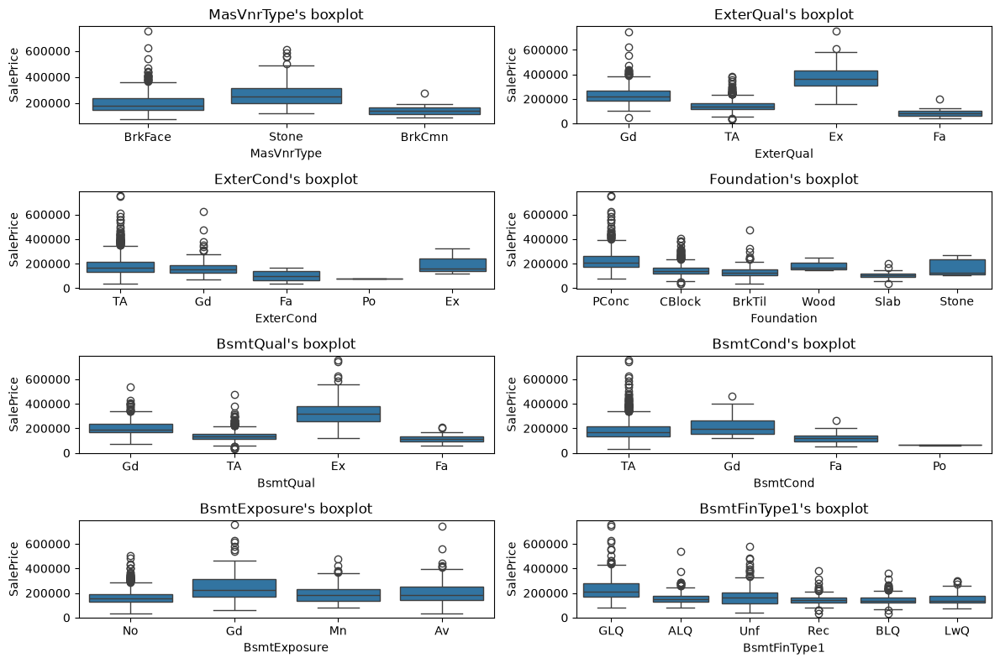

In [24]:
cat_features_list = cat_features[16:24]
fig, axes = plt.subplots(4, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_features_list):
    sns.boxplot(data=df_train, x=col, y=TARGET, ax=ax)
    ax.set_title(f'{col}\'s boxplot')
    
plt.tight_layout()

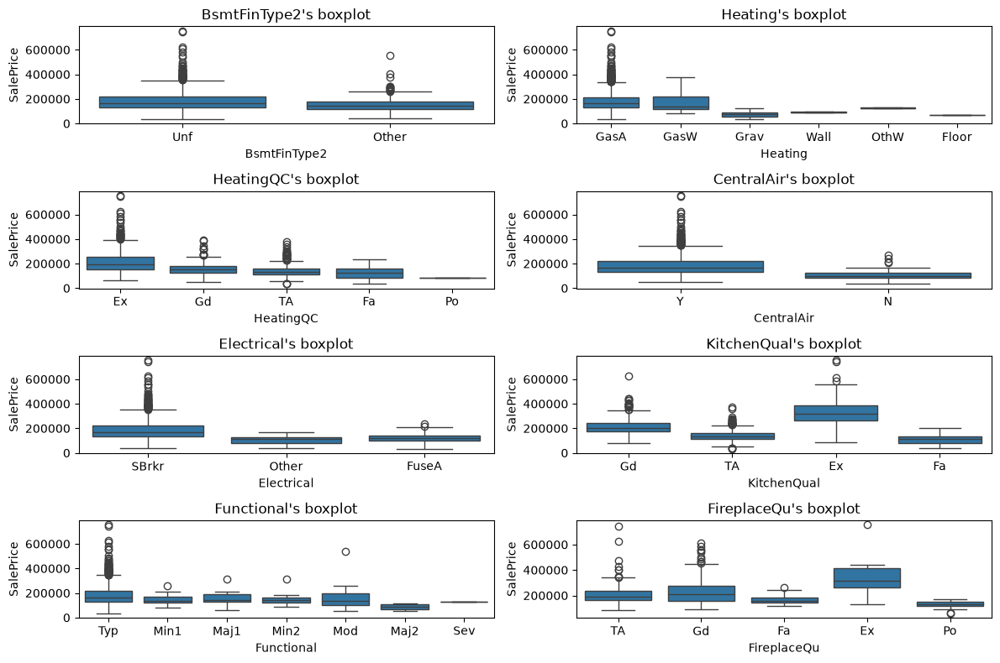

In [25]:
cat_features_list = cat_features[24:32]
fig, axes = plt.subplots(4, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_features_list):
    sns.boxplot(data=df_train, x=col, y=TARGET, ax=ax)
    ax.set_title(f'{col}\'s boxplot')
    
plt.tight_layout()

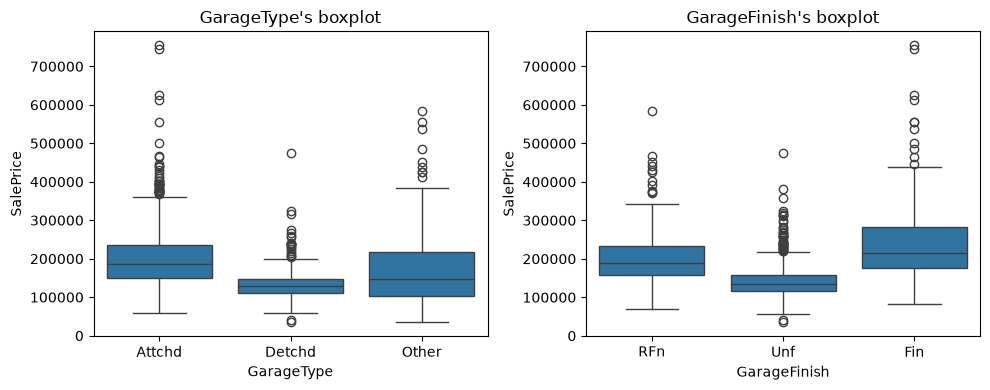

In [26]:
cat_features_list = cat_features[32:]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, cat_features_list):
    sns.boxplot(data=df_train, x=col, y=TARGET, ax=ax)
    ax.set_title(f'{col}\'s boxplot')
    
plt.tight_layout()

In [27]:
df_train = df_train.drop(columns=['GarageCond', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Utilities', 'LandSlope', 'LotShape', 'LotConfig', 'GarageFinish'])

In [28]:
cat_features = df_train.select_dtypes(str).columns.to_list()
cat_gap_features = df_train[cat_features].isna().sum().sort_values(ascending=False).head(3).index.to_list()

In [29]:
df_train[cat_gap_features] = df_train[cat_gap_features].fillna(df_train[cat_gap_features].mode())
for col in cat_gap_features:
    df_train[col] = df_train[col].fillna(df_train[col].mode()[0])

In [30]:
df_train.isna().sum().sort_values(ascending=False).sum()

np.int64(0)

## Target Analysis

<Axes: xlabel='SalePrice', ylabel='Count'>

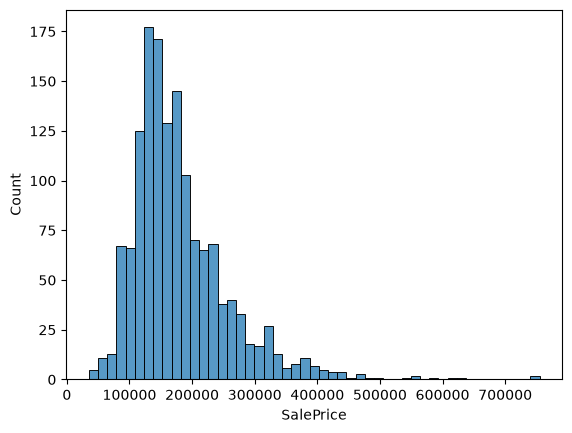

In [150]:
sns.histplot(data=df_train, x=TARGET)

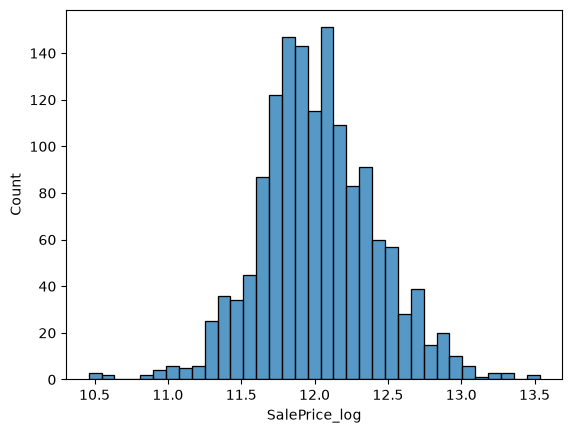

In [152]:
df_train['SalePrice_log'] = np.log1p(df_train[TARGET])
sns.histplot(data=df_train, x='SalePrice_log')
LOG_TARGET = 'SalePrice_log'

In [177]:
df_train_enc = pd.get_dummies(df_train, drop_first=True)
print(df_train.shape)

(1460, 63)


## Model Training
### Data splitting

In [107]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [154]:
X_enc = df_train_enc.drop(columns=[TARGET, LOG_TARGET])
X = df_train.drop(columns=[TARGET, LOG_TARGET])

y = df_train_enc[LOG_TARGET]

X_enc_train, X_enc_val, y_train, y_val = train_test_split(X_enc, y, test_size=0.2, random_state=42, shuffle=True)

### Baseline model checking (Linear Regression)

In [155]:
baseline = LinearRegression()
baseline.fit(X_enc_train, y_train)

bsln_pred_train = baseline.predict(X_enc_train)
bsln_pred_val = baseline.predict(X_enc_val)
print(f'baseline train RMSE: {root_mean_squared_error(y_train, bsln_pred_train):.3f}')
print(f'baseline validation RMSE: {root_mean_squared_error(y_val, bsln_pred_val):.3f}')

baseline train RMSE: 0.109
baseline validation RMSE: 0.136


### XGBoost and CatBoost models training

In [36]:
from xgboost import XGBRegressor

In [103]:
xgb_model = XGBRegressor(n_jobs=-1, random_state=42)

xgb_param_grid = {
    'max_depth': [3, 5],
    'learning_rate' : [0.01, 0.03, 0.1, 0.3],
    'n_estimators' : [700, 900, 1200],
    'eval_metric' : ['rmse'],
    'subsample': [0.9],
    'reg_lambda' : [1, 3, 7],
    'gamma' : [0.1, 0.3]
}

xgb_grid = GridSearchCV(xgb_model, xgb_param_grid, cv=5)

In [104]:
xgb_grid.fit(X_enc_train, y_train)

KeyboardInterrupt: 

In [64]:
xgb_best_model = xgb_grid.best_estimator_
xgb_preds_train = xgb_best_model.predict(X_enc_train)
xgb_preds_val = xgb_best_model.predict(X_enc_val)

print(f'xgb train RMSE: {root_mean_squared_error(y_train, xgb_preds_train):.3f}')
print(f'xgb validation RMSE: {root_mean_squared_error(y_val, xgb_preds_val):.3f}')
print(xgb_best_model.get_params())

xgb train RMSE: 4174.361
xgb validation RMSE: 26618.688
{'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 3, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 900, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


In [156]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

In [157]:
from catboost import CatBoostRegressor

In [158]:
cat_model = CatBoostRegressor(thread_count=-1, cat_features=cat_features, iterations=2000, early_stopping_rounds=50)

cat_param_grid = {
    'depth': [3, 5, 6],
    'learning_rate' : [0.01, 0.03],
    'l2_leaf_reg' : [3, 5, 10],
    'random_strength' : [1, 2],
}


In [159]:
results = cat_model.grid_search(param_grid=cat_param_grid, X=X_train, y=y_train, cv=5)


0:	learn: 11.9133866	test: 11.9390817	best: 11.9390817 (0)	total: 4.09ms	remaining: 8.17s
1:	learn: 11.7960101	test: 11.8217492	best: 11.8217492 (1)	total: 7.2ms	remaining: 7.19s
2:	learn: 11.6810355	test: 11.7062292	best: 11.7062292 (2)	total: 10.2ms	remaining: 6.78s
3:	learn: 11.5665053	test: 11.5913777	best: 11.5913777 (3)	total: 12.5ms	remaining: 6.24s
4:	learn: 11.4524806	test: 11.4771947	best: 11.4771947 (4)	total: 14.4ms	remaining: 5.76s
5:	learn: 11.3388050	test: 11.3634301	best: 11.3634301 (5)	total: 15.4ms	remaining: 5.13s
6:	learn: 11.2280760	test: 11.2524515	best: 11.2524515 (6)	total: 16.9ms	remaining: 4.82s
7:	learn: 11.1175902	test: 11.1416271	best: 11.1416271 (7)	total: 19.3ms	remaining: 4.81s
8:	learn: 11.0080065	test: 11.0318374	best: 11.0318374 (8)	total: 21.7ms	remaining: 4.81s
9:	learn: 10.9007015	test: 10.9242871	best: 10.9242871 (9)	total: 23.6ms	remaining: 4.7s
10:	learn: 10.7934422	test: 10.8170013	best: 10.8170013 (10)	total: 25.1ms	remaining: 4.54s
11:	learn:

In [161]:
cat_best_model = cat_model
cat_preds_train = cat_best_model.predict(X_train)
cat_preds_val = cat_best_model.predict(X_val)

print(f'catboost train RMSE: {root_mean_squared_error(y_train, cat_preds_train):.3f}')
print(f'catboost validation RMSE: {root_mean_squared_error(y_val, cat_preds_val):.3f}')


catboost train RMSE: 0.077
catboost validation RMSE: 0.129


In [164]:
cat_test_preds = np.expm1(cat_model.predict(X_val))
print(f'catboost validation RMSE: {root_mean_squared_error(np.expm1(y_val), cat_test_preds):.3f}')

catboost validation RMSE: 27573.279


# TEST PREDICTIONS

In [218]:
df_test = pd.read_csv(r'../data/test.csv')

In [219]:
df_test['LotFrontage'] = df_test['LotFrontage'].fillna(df_test['LotFrontage'].mean())
df_test['GarageYrBlt'] = df_test['GarageYrBlt'].fillna(df_test['GarageYrBlt'].mean())
df_test['MasVnrArea'] = df_test['MasVnrArea'].fillna(df_test['MasVnrArea'].mode()[0])

df_test.loc[~df_test['GarageQual'].isin(['TA', 'Fa']), 'GarageQual'] = 'Other'
df_test.loc[~df_test['Electrical'].isin(['SBrkr', 'FuseA']), 'Electrical'] = 'Other'
df_test.loc[~df_test['GarageType'].isin(['Attchd', 'Detchd', 'Builtin']), 'GarageType'] = 'Other'
df_test.loc[df_test['BsmtFinType2'] != 'Unf', 'BsmtFinType2'] = 'Other'

for col in cat_gap_features:
    df_train[col] = df_train[col].fillna(df_train[col].mode()[0])

In [220]:
id_col = df_test['Id']
df_test = df_test.drop(columns=['PoolQC', 'MiscFeature', 'Alley', 'Id', 'Fence', 'GarageYrBlt', 'TotRmsAbvGrd', 'GarageCars', '1stFlrSF', 'GarageCond', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Utilities', 'LandSlope', 'LotShape', 'LotConfig', 'GarageFinish'])

In [221]:
for col in df_test.columns:
    if df_test[col].isna().any():
        df_test[col] = df_test[col].fillna(df_test[col].mode()[0])

In [237]:
test_preds = np.expm1(cat_model.predict(df_test))

df = pd.DataFrame({
    'Id' : id_col,
    'SalePrice' : test_preds
})

display(df)

df.to_csv('../data/predictions.csv', index=False)

,Id,SalePrice
0,1461,124896.194474
1,1462,155763.960728
2,1463,185159.209789
3,1464,186419.856033
4,1465,195290.798405
...,...,...
1454,2915,85228.169230
1455,2916,84880.117441
1456,2917,174331.833190
1457,2918,116890.565842
